###  Libraries

In [1]:
# Import libraries
import numpy as np
import torch
import sys
from Datasets.Datasets import get_dataset
from Autoencoder import Autoencoder, CD_Autoencoder
from Visualization import Visualization
from General_Functions import General_Functions

### Global Variables

In [2]:
# Set path to module
path_to_module = './'
sys.path.append(path_to_module)

# Set device (cuda or cpu)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_device(device)

# Set random seeds (runs repeat only from a fresh kernel with all cells run in order) - for more info look here : https://docs.pytorch.org/docs/2.15/notes/randomness.html
seed = 42
torch.manual_seed(seed) # torch, CPU and GPU: layer weights, RBF centres, batch order of the dataloader
np.random.seed(seed) # numpy: k-means initialization, t-SNE, plot colours . Careful , when dataset = "synthetic" it overrides the seed to 42 !!!
torch.backends.cudnn.deterministic = True # GPU: cuDNN uses only deterministic convolution algorithms
torch.backends.cudnn.benchmark = False # GPU: cuDNN does not test and pick a (possibly different) fastest algorithm each run

### Visualization

In [3]:
visualization = Visualization()

### Load Dataset

In [4]:
# Set dataset_name, module_name, batch_size and n_clusters
dataset_name = "emnist_balanced_digits" # The available datasets are: emnist_balanced_digits, emnist_mnist, emnist_balanced_letters_A_J, emnist_balanced_letters_K_T, emnist_balanced_letters_U_Z, har, pendigits, waveform_v1, synthetic
batch_size = 256
n_clusters = 10

# Get dataloader, input_dim, data_np and labels
dataloader, input_dim, data_np, labels = get_dataset(dataset_name, batch_size)
print('Data_Shape is:', input_dim) # for image datasets , data shape == channel
print('Batches Number is:', len(dataloader))
print(np.unique(labels))

Data_Shape is: 1
Batches Number is: 110
[0 1 2 3 4 5 6 7 8 9]


### Constraint Matrix

### Parameters

In [5]:
# Set latent dimension and negative slope
latent_dim = 10
negative_slope = 0

# Set pre-training epochs and learning rate
n_pret_epochs = 100
pret_lr = 1e-3

# Set lamdas, training epochs and learning rate
sil_lambda = 0.01 # 0.01
entr_lambda = 0.01 # 0.01
semi_lambda =  0.8
n_epochs = 100
lr = 5e-4

# Set use_pretrain and is_mlp_ae
use_pretrain = True # Set True for pretraining autoencoder or set False for using already pretrained weights
is_mlp_ae = False # Set True for tabular datasets e.g. pendigits or set False for image datasets e.g. emnist_mnist

### Create Autoencoder Model

In [6]:
if is_mlp_ae:
    autoencoder = Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)
else:
    autoencoder = CD_Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)

autoencoder.set_general_training_variables(dataloader=dataloader, batch_size=batch_size)
autoencoder.set_pretraining_variables(n_pret_epochs=n_pret_epochs, pret_lr=pret_lr)
autoencoder.set_training_variables(n_epochs=n_epochs, lr=lr, sil_lambda=sil_lambda, entr_lambda=entr_lambda)
autoencoder.set_path_variables(path_to_module=path_to_module, dataset_name=dataset_name)
autoencoder.set_path()
autoencoder = autoencoder.to(device)

### Pretrain Autoencoder

In [7]:
if(use_pretrain):
    autoencoder.pretrain_autoencoder()
    autoencoder.save_pretrained_weights()
else:
    model_save_path = autoencoder.data_dir_path + '/Weigths/autoencoder_weights.pth'
    autoencoder.load_state_dict(torch.load(model_save_path))

Epoch: 0, Loss: 60.619231
Epoch: 1, Loss: 37.288135
Epoch: 2, Loss: 25.842145
Epoch: 3, Loss: 17.850546
Epoch: 4, Loss: 12.089196
Epoch: 5, Loss: 8.186283
Epoch: 6, Loss: 5.531970
Epoch: 7, Loss: 3.855345
Epoch: 8, Loss: 2.832812
Epoch: 9, Loss: 2.257605
Epoch: 10, Loss: 1.912969
Epoch: 11, Loss: 1.752791
Epoch: 12, Loss: 1.640287
Epoch: 13, Loss: 1.600353
Epoch: 14, Loss: 1.570038
Epoch: 15, Loss: 1.547202
Epoch: 16, Loss: 1.553206
Epoch: 17, Loss: 1.524929
Epoch: 18, Loss: 1.518319
Epoch: 19, Loss: 1.501837
Epoch: 20, Loss: 1.512437
Epoch: 21, Loss: 1.489214
Epoch: 22, Loss: 1.479689
Epoch: 23, Loss: 1.463816
Epoch: 24, Loss: 1.459030
Epoch: 25, Loss: 1.456840
Epoch: 26, Loss: 1.437228
Epoch: 27, Loss: 1.427104
Epoch: 28, Loss: 1.424249
Epoch: 29, Loss: 1.412555
Epoch: 30, Loss: 1.427944
Epoch: 31, Loss: 1.407453
Epoch: 32, Loss: 1.408627
Epoch: 33, Loss: 1.391885
Epoch: 34, Loss: 1.381514
Epoch: 35, Loss: 1.354319
Epoch: 36, Loss: 1.354825
Epoch: 37, Loss: 1.346545
Epoch: 38, Loss: 

### Initialize the clustering layer using k-means

In [8]:
autoencoder.kmeans_initialization(n_init=100)

ACC: 0.81 PUR: 0.81 NMI: 0.74 ARI: 0.67


### Train Autoencoder

In [9]:
# Constraints are computed live in training: each batch's constraint block is built from that batch's labels
latent_data, labels, clustering = autoencoder.train_semi_supervised_autoencoder(semi_lambda=semi_lambda)

Ep: 0 Rec L: 5.7789 Cl L: 1.1459 Entropy: 3.6064 SSil: -0.0459 Semi L: -369822.7551 ACC: 0.91 PUR: 0.91 NMI: 0.85 ARI: 0.83
Ep: 1 Rec L: 6.6987 Cl L: 1.1347 Entropy: 3.6172 SSil: -0.0347 Semi L: -424540.0461 ACC: 0.85 PUR: 0.85 NMI: 0.81 ARI: 0.72
Ep: 2 Rec L: 6.7148 Cl L: 1.1327 Entropy: 3.5997 SSil: -0.0327 Semi L: -477906.1729 ACC: 0.60 PUR: 0.60 NMI: 0.72 ARI: 0.53
Ep: 3 Rec L: 6.7403 Cl L: 1.1227 Entropy: 3.6249 SSil: -0.0227 Semi L: -535280.6934 ACC: 0.47 PUR: 0.47 NMI: 0.62 ARI: 0.37
Ep: 4 Rec L: 6.7695 Cl L: 1.1098 Entropy: 3.6485 SSil: -0.0098 Semi L: -596799.4516 ACC: 0.41 PUR: 0.41 NMI: 0.62 ARI: 0.34
Ep: 5 Rec L: 6.7969 Cl L: 1.1038 Entropy: 3.6534 SSil: -0.0038 Semi L: -662761.2613 ACC: 0.40 PUR: 0.40 NMI: 0.63 ARI: 0.36
Ep: 6 Rec L: 6.8332 Cl L: 1.1017 Entropy: 3.6540 SSil: -0.0017 Semi L: -733087.1969 ACC: 0.36 PUR: 0.36 NMI: 0.56 ARI: 0.28
Ep: 7 Rec L: 6.8694 Cl L: 1.1011 Entropy: 3.6540 SSil: -0.0011 Semi L: -807767.8410 ACC: 0.30 PUR: 0.30 NMI: 0.49 ARI: 0.20
Ep: 8 Re

### Save Clustering Results

In [10]:
General_Functions().save_excel(autoencoder.data_dir_path, autoencoder.df_eval)

Directory './Results/emnist_balanced_digits/SSAE/100_Eps_ld_10_out_10_bs_256_lr_0.0005_sil_lambda_0.01_entr_lambda_0.01' already exists.


### Plot Clustering Results

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 28010 samples in 0.013s...
[t-SNE] Computed neighbors for 28010 samples in 0.318s...
[t-SNE] Computed conditional probabilities for sample 1000 / 28010
[t-SNE] Computed conditional probabilities for sample 2000 / 28010
[t-SNE] Computed conditional probabilities for sample 3000 / 28010
[t-SNE] Computed conditional probabilities for sample 4000 / 28010
[t-SNE] Computed conditional probabilities for sample 5000 / 28010
[t-SNE] Computed conditional probabilities for sample 6000 / 28010
[t-SNE] Computed conditional probabilities for sample 7000 / 28010
[t-SNE] Computed conditional probabilities for sample 8000 / 28010
[t-SNE] Computed conditional probabilities for sample 9000 / 28010
[t-SNE] Computed conditional probabilities for sample 10000 / 28010
[t-SNE] Computed conditional probabilities for sample 11000 / 28010
[t-SNE] Computed conditional probabilities for sample 12000 / 28010
[t-SNE] Computed conditional probabilities for sam

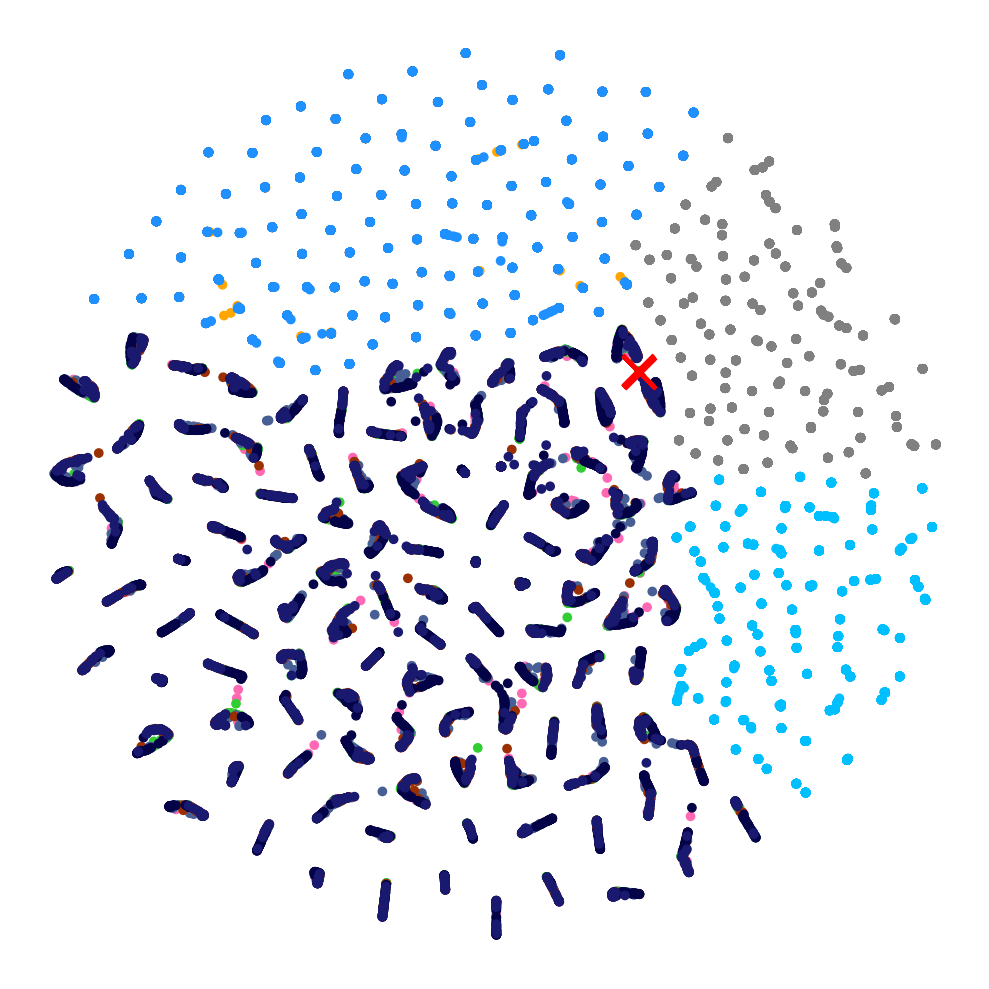

In [11]:
cluster_centers = autoencoder.get_cluster_centers().cpu().detach().numpy()
data, latent_data, labels = autoencoder.get_latent_data()
visualization.plot_tsne(latent_data, labels, clustering, cluster_centers, autoencoder.data_dir_path)